In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/titanic-dataset/Titanic-Dataset.csv


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [3]:
titanic = pd.read_csv('/kaggle/input/titanic-dataset/Titanic-Dataset.csv')
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
titanic.shape

(891, 12)

In [5]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
titanic.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [7]:
titanic = titanic.drop(columns='Cabin', axis=1)

In [8]:
titanic['Embarked'].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [9]:
titanic.fillna(titanic['Embarked'].mode()[0], inplace=True)

/tmp/ipykernel_34/951666266.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'S' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  titanic.fillna(titanic['Embarked'].mode()[0], inplace=True)


In [10]:
titanic['Embarked'].value_counts()

Embarked
S    646
C    168
Q     77
Name: count, dtype: int64

In [11]:
titanic['Age'].value_counts()

Age
S       177
24.0     30
22.0     27
18.0     26
30.0     25
       ... 
36.5      1
23.5      1
0.92      1
53.0      1
74.0      1
Name: count, Length: 89, dtype: int64

In [12]:
# Convert 'Age' column to numeric if necessary and fill missing values with mean
titanic['Age'] = pd.to_numeric(titanic['Age'], errors='coerce') 
titanic.fillna(titanic['Age'].mean(), inplace=True)

In [13]:
print(titanic['Age'].mean())

29.69911764705882


In [14]:
titanic['Age'].value_counts()

Age
29.699118    177
24.000000     30
22.000000     27
18.000000     26
30.000000     25
            ... 
36.500000      1
23.500000      1
0.920000       1
53.000000      1
74.000000      1
Name: count, Length: 89, dtype: int64

In [15]:
titanic.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [16]:
titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.002015,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,29.699118,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [17]:
titanic['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [18]:
titanic['Embarked'].value_counts()

Embarked
S    646
C    168
Q     77
Name: count, dtype: int64

In [19]:
sns.set()

<Axes: xlabel='Survived', ylabel='count'>

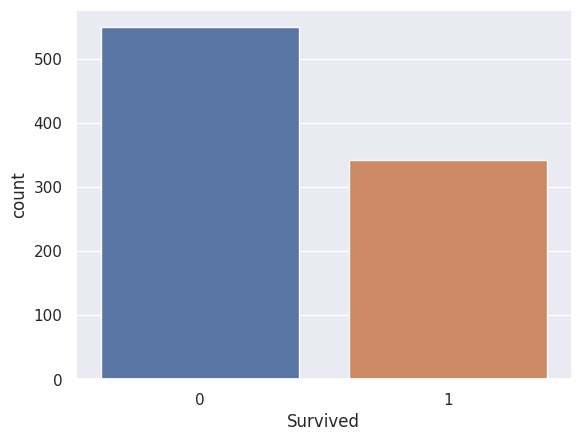

In [20]:
sns.countplot(titanic, x='Survived')

<Axes: xlabel='Sex', ylabel='count'>

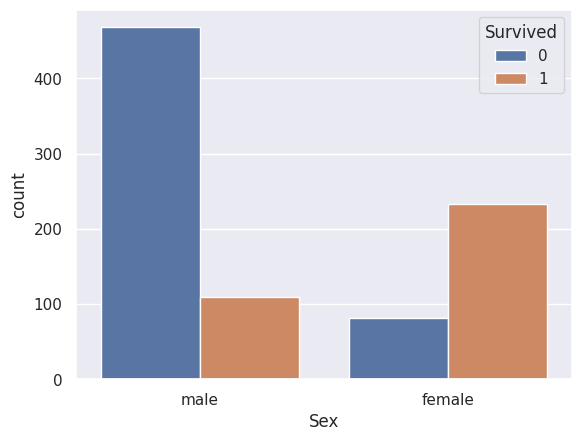

In [21]:
sns.countplot(titanic, x='Sex', hue='Survived')

<Axes: xlabel='Embarked', ylabel='count'>

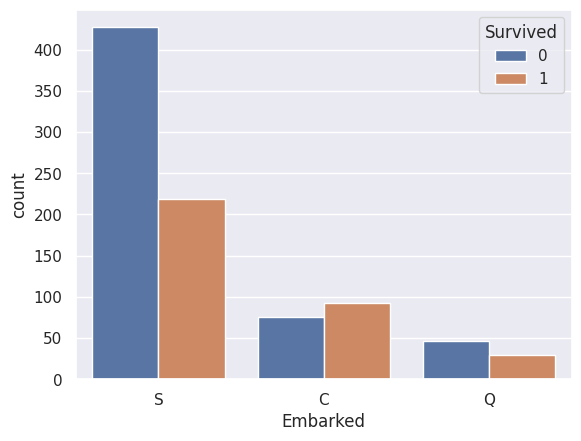

In [22]:
sns.countplot(titanic, x='Embarked', hue='Survived')

<Axes: xlabel='Pclass', ylabel='count'>

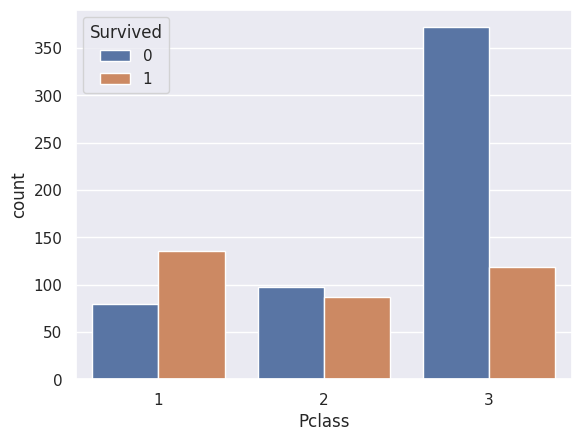

In [23]:
sns.countplot(titanic, x='Pclass', hue='Survived')

In [24]:
titanic['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [25]:
titanic['Embarked'].value_counts()

Embarked
S    646
C    168
Q     77
Name: count, dtype: int64

In [26]:
titanic.replace({'Sex':{'male':0,'female':1}, 'Embarked':{'S':0, 'C':1, 'Q':2}}, inplace=True)

/tmp/ipykernel_34/57511097.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  titanic.replace({'Sex':{'male':0,'female':1}, 'Embarked':{'S':0, 'C':1, 'Q':2}}, inplace=True)


In [27]:
titanic['Embarked'].value_counts()

Embarked
0    646
1    168
2     77
Name: count, dtype: int64

In [28]:
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,1
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,0
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,0


In [31]:
X = titanic.drop(['PassengerId', 'Name', 'Ticket', 'Survived'], axis=1)  # Features
Y = titanic['Survived']  # Target variable

In [33]:
print(X)
print(Y)

     Pclass  Sex        Age  SibSp  Parch     Fare  Embarked
0         3    0  22.000000      1      0   7.2500         0
1         1    1  38.000000      1      0  71.2833         1
2         3    1  26.000000      0      0   7.9250         0
3         1    1  35.000000      1      0  53.1000         0
4         3    0  35.000000      0      0   8.0500         0
..      ...  ...        ...    ...    ...      ...       ...
886       2    0  27.000000      0      0  13.0000         0
887       1    1  19.000000      0      0  30.0000         0
888       3    1  29.699118      1      2  23.4500         0
889       1    0  26.000000      0      0  30.0000         1
890       3    0  32.000000      0      0   7.7500         2

[891 rows x 7 columns]
0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64


In [37]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=5)

In [38]:
print("Training set shape:", X_train.shape, Y_train.shape)
print("Testing set shape:", X_test.shape, Y_test.shape)

Training set shape: (712, 7) (712,)
Testing set shape: (179, 7) (179,)


In [40]:
from sklearn.linear_model import LogisticRegression

In [45]:
model = LogisticRegression()

In [46]:
model.fit(X_train, Y_train)

/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [67]:
from sklearn.metrics import confusion_matrix
pred = model.predict(X_test)
print(pred)

[0 0 0 0 0 0 1 0 1 0 0 1 0 1 0 1 0 1 0 0 0 1 1 1 1 0 0 0 0 0 0 1 1 0 1 1 0
 0 0 0 0 1 0 0 0 0 1 1 0 0 0 1 1 0 0 0 0 0 0 1 0 0 1 0 1 0 0 0 1 0 1 0 1 0
 1 0 0 1 1 1 0 0 0 0 1 1 0 1 0 0 0 0 1 0 1 0 1 0 0 0 0 1 0 0 1 1 0 0 0 1 0
 0 1 0 1 0 1 0 1 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 1 1 0 1
 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 1 1 0 0 0 1 0]


In [68]:
from sklearn.metrics import confusion_matrix
pred1 = model.predict(X_train)
print(pred1)

[1 1 1 0 0 1 0 1 0 1 0 0 1 0 0 0 0 0 1 0 0 1 0 0 0 0 1 0 0 0 0 0 1 1 0 0 0
 0 0 0 0 0 0 1 1 1 1 1 1 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 1 1 0 0 0 0
 0 0 0 0 0 1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 0 1 0 0 0 0 1 0 0 1 0 0 0 0 0 0
 0 0 0 1 0 1 1 1 0 1 0 0 0 0 0 1 1 1 0 1 0 0 0 0 0 0 1 0 0 1 0 0 0 0 1 1 1
 1 1 0 0 0 1 0 1 0 1 0 0 1 1 0 1 1 1 0 0 1 0 1 0 0 0 0 0 0 0 1 1 1 1 0 1 0
 0 0 0 0 1 0 0 1 0 0 0 1 0 1 0 1 1 0 1 0 0 1 1 1 1 0 1 1 1 0 0 0 0 0 1 0 0
 0 0 0 1 0 0 1 0 0 1 0 0 1 1 0 1 1 0 0 1 1 1 0 0 1 0 0 0 1 1 0 1 1 0 0 1 0
 1 1 0 1 1 0 1 0 0 1 0 0 0 0 1 0 0 1 0 1 1 1 0 1 0 0 0 0 1 0 1 1 0 0 0 0 1
 1 1 0 1 1 1 0 1 1 0 0 1 0 0 0 0 1 0 0 1 1 0 0 0 0 0 1 0 1 1 0 0 0 1 0 0 1
 1 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 1 0 1 0 1 0 0 1 1 0 1 0 0 0 0 1 0 0 0 0
 0 0 0 0 0 0 1 0 1 0 0 0 0 1 1 0 0 0 1 1 1 1 0 1 1 1 0 1 0 1 0 1 0 0 1 1 1
 1 0 1 1 0 0 1 0 1 0 0 0 0 0 1 1 0 0 1 1 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1
 0 1 1 0 1 0 0 0 0 1 0 0 1 1 1 1 1 0 0 1 0 1 1 0 0 0 0 0 1 0 1 0 0 1 1 1 1
 0 1 1 1 0 1 1 0 0 0 0 0 

[[98 13]
 [21 47]]


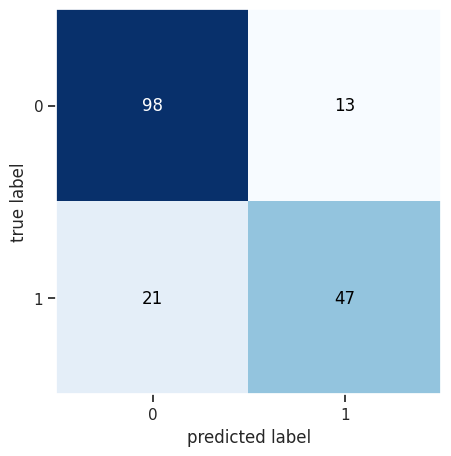

In [52]:
cm = confusion_matrix(Y_test,pred)
print(cm)
from mlxtend.plotting import plot_confusion_matrix
ax = plot_confusion_matrix(conf_mat=cm,figsize=(5,5))
plt.show()

[[368  70]
 [ 78 196]]


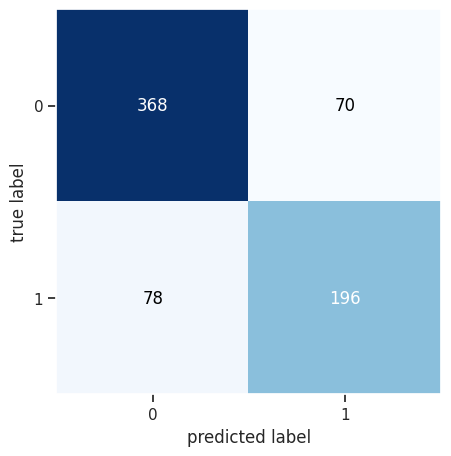

In [55]:
cm = confusion_matrix(Y_train,pred1)
print(cm)
from mlxtend.plotting import plot_confusion_matrix
ax = plot_confusion_matrix(conf_mat=cm,figsize=(5,5))
plt.show()

In [61]:
from sklearn.metrics import classification_report
crc = classification_report(Y_train,pred1)
print(crc)

              precision    recall  f1-score   support

           0       0.83      0.84      0.83       438
           1       0.74      0.72      0.73       274

    accuracy                           0.79       712
   macro avg       0.78      0.78      0.78       712
weighted avg       0.79      0.79      0.79       712



In [70]:
from sklearn.metrics import classification_report
crc = classification_report(Y_test,pred)
print(crc)

              precision    recall  f1-score   support

           0       0.82      0.88      0.85       111
           1       0.78      0.69      0.73        68

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.81      0.81      0.81       179



In [65]:
training_prediction=accuracy_score(Y_train,pred1)
print('Accuracy of training data is :',training_prediction)

Accuracy of training data is : 0.7921348314606742


In [69]:
testing_prediction=accuracy_score(Y_test,pred)
print('Accuracy of test data is :',testing_prediction)

Accuracy of test data is : 0.8100558659217877


In [71]:
print(X)

     Pclass  Sex        Age  SibSp  Parch     Fare  Embarked
0         3    0  22.000000      1      0   7.2500         0
1         1    1  38.000000      1      0  71.2833         1
2         3    1  26.000000      0      0   7.9250         0
3         1    1  35.000000      1      0  53.1000         0
4         3    0  35.000000      0      0   8.0500         0
..      ...  ...        ...    ...    ...      ...       ...
886       2    0  27.000000      0      0  13.0000         0
887       1    1  19.000000      0      0  30.0000         0
888       3    1  29.699118      1      2  23.4500         0
889       1    0  26.000000      0      0  30.0000         1
890       3    0  32.000000      0      0   7.7500         2

[891 rows x 7 columns]


In [73]:
import warnings
warnings.filterwarnings('ignore')
res=model.predict([[3,0,35,0,0,13,0]])
if (res==0):
    print('Not Survived Sorry')
else:
    print('Survived')

Not Survived Sorry
